In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import joblib

In [2]:
DATASET_PATH = "leapGestRecog"

In [3]:
import os
print(os.getcwd())
print(os.listdir())

c:\Users\krishna\Documents\Python codes\PRODIGY_ML_04
['Hand_Gesture_Recognition.ipynb', 'leapGestRecog']


In [4]:
import os

print(os.listdir("leapGestRecog"))

['00', '01', '02', '03', '04', '05', '06', '07']


In [5]:
import os
import cv2
import numpy as np

DATASET_PATH = "leapGestRecog"

IMG_SIZE = 64

data = []
labels = []

MAX_IMAGES = 20   # Har gesture folder se sirf 200 images

for person in os.listdir(DATASET_PATH):

    person_path = os.path.join(DATASET_PATH, person)

    if not os.path.isdir(person_path):
        continue

    for gesture in os.listdir(person_path):

        gesture_path = os.path.join(person_path, gesture)

        label = gesture

        count = 0

        for img in os.listdir(gesture_path):

            if count >= MAX_IMAGES:
                break

            img_path = os.path.join(gesture_path, img)

            image = cv2.imread(img_path)

            if image is None:
                continue

            image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))

            data.append(image.flatten())
            labels.append(label)

            count += 1

data = np.array(data)
labels = np.array(labels)

print("Total Images :", len(data))
print("Total Classes :", len(np.unique(labels)))

Total Images : 1500
Total Classes : 10


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    data,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Training Images:", len(X_train))
print("Testing Images:", len(X_test))

Training Images: 1200
Testing Images: 300


In [9]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(max_iter=5000, random_state=42)

svm_model.fit(X_train, y_train)

print("Training Completed!")

Training Completed!


C:\Users\krishna\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [10]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = svm_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

Accuracy: 0.9933333333333333

Classification Report:

               precision    recall  f1-score   support

      01_palm       1.00      1.00      1.00        32
         02_l       0.97      1.00      0.98        32
      03_fist       1.00      1.00      1.00        32
04_fist_moved       0.97      1.00      0.98        32
     05_thumb       1.00      0.97      0.98        32
     06_index       1.00      1.00      1.00        28
        07_ok       1.00      0.96      0.98        28
08_palm_moved       1.00      1.00      1.00        28
         09_c       1.00      1.00      1.00        28
      10_down       1.00      1.00      1.00        28

     accuracy                           0.99       300
    macro avg       0.99      0.99      0.99       300
 weighted avg       0.99      0.99      0.99       300



In [11]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[32  0  0  0  0  0  0  0  0  0]
 [ 0 32  0  0  0  0  0  0  0  0]
 [ 0  0 32  0  0  0  0  0  0  0]
 [ 0  0  0 32  0  0  0  0  0  0]
 [ 0  0  0  1 31  0  0  0  0  0]
 [ 0  0  0  0  0 28  0  0  0  0]
 [ 0  1  0  0  0  0 27  0  0  0]
 [ 0  0  0  0  0  0  0 28  0  0]
 [ 0  0  0  0  0  0  0  0 28  0]
 [ 0  0  0  0  0  0  0  0  0 28]]


In [12]:
import joblib

joblib.dump(svm_model, "gesture_model.pkl")

print("Model Saved Successfully!")

Model Saved Successfully!


In [13]:
print("Dataset Shape:", data.shape)
print("Number of Classes:", len(np.unique(labels)))
print("Classes:", np.unique(labels))

Dataset Shape: (1500, 12288)
Number of Classes: 10
Classes: ['01_palm' '02_l' '03_fist' '04_fist_moved' '05_thumb' '06_index' '07_ok'
 '08_palm_moved' '09_c' '10_down']


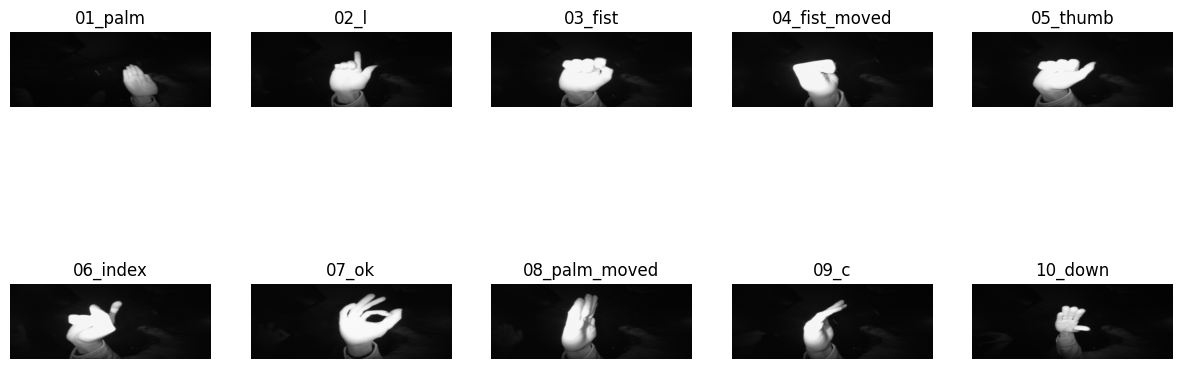

In [14]:
import matplotlib.pyplot as plt
import cv2
import os

sample_images = []

for person in os.listdir(DATASET_PATH):
    person_path = os.path.join(DATASET_PATH, person)

    if not os.path.isdir(person_path):
        continue

    for gesture in os.listdir(person_path):
        gesture_path = os.path.join(person_path, gesture)

        img_name = os.listdir(gesture_path)[0]
        img_path = os.path.join(gesture_path, img_name)

        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        sample_images.append((gesture, image))

        if len(sample_images) == 10:
            break

    if len(sample_images) == 10:
        break

plt.figure(figsize=(15,6))

for i, (label, image) in enumerate(sample_images):
    plt.subplot(2,5,i+1)
    plt.imshow(image)
    plt.title(label)
    plt.axis("off")

plt.show()

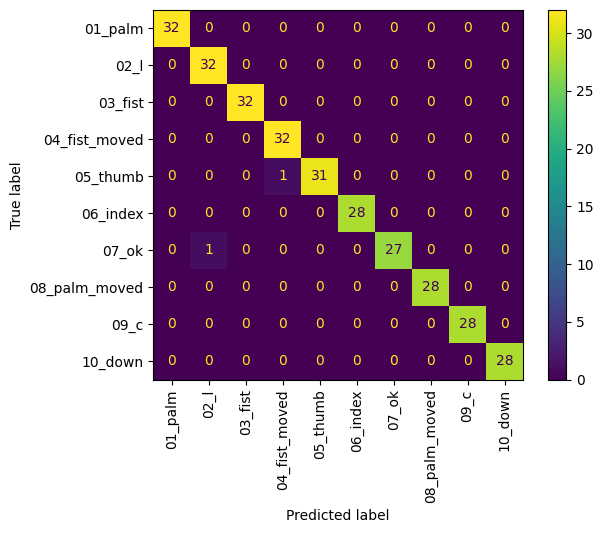

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=90
)

plt.show()

In [16]:
import joblib

joblib.dump(svm_model, "gesture_model.pkl")

print("Model Saved Successfully!")

Model Saved Successfully!


In [18]:
image_path = "leapGestRecog/00/01_palm/frame_00_01_0001.png"

img = cv2.imread(image_path)

if img is None:
    print("Image not found!")
else:
    img = cv2.resize(img, (64,64))
    img = img.flatten().reshape(1,-1)

    prediction = svm_model.predict(img)

    print("Predicted Gesture:", prediction[0])

Predicted Gesture: 01_palm
